In [1]:
from pathlib import Path

print("Рабочая папка:", Path.cwd())
print("Папка data существует:", Path("data").is_dir())
print("Найдено папок:", len(list(Path("data").glob("dataset_*"))))

Рабочая папка: C:\Users\chand\Documents\GitHub\Car-price-prediction
Папка data существует: True
Найдено папок: 48


# 1. Подготовка данных

Восстанавливаем обучающую таблицу из 48 наборов файлов (`CSV`, `JSON`, `Excel`, `Parquet`), объединяем по `car_id` и сохраняем `full_dataset.csv` в локальной папке `data/`.

> Исходные данные не включены в репозиторий. Перед запуском следуйте инструкциям из README.md.

In [2]:
from pathlib import Path
import pandas as pd

# Путь к папке data/ в корне репозитория (исходные данные не публикуются)
root = Path("data")

#Общая таблица pandas для объединения 
data_frame = []

#Для каждой папки из отсрортированного порядка папок dataset_1, dataset_2 и так далее
for folder in sorted(root.glob("dataset_*")):
    #Создаем список из одного файла
    files = list(folder.glob("data.*"))
    #Так как в каждой папке один файл берем первый элемент из списка
    file = files[0]
    print(f"Читаю {folder.name}/{file.name}")
    #Пробуем прочитать файл в разных форматах
    try:
        if file.suffix == ".csv":
            df = pd.read_csv(file)
        elif file.suffix == ".xlsx":
            df = pd.read_excel(file)
        elif file.suffix == ".json":
            df = pd.read_json(file)
        elif file.suffix == ".parquet":
            df = pd.read_parquet(file)
        else:
            print(f"Неизвестный формат {file.suffix}")
        #Добавляем считанную таблицу в конец списка.
        data_frame.append(df)
    #Отработка если что то пошло не так
    except Exception as e:
        print(f"Ошибка в {file.name}: {e}")

#Объединяем все таблицы в одну, параметр не сохраняет старые номера строк
dataset = pd.concat(data_frame, ignore_index=True)
#Выводим статистику
print("\nПосле объединения таблиц")
print("Строк:", len(dataset))
print("Уникальных car_id:", dataset["car_id"].nunique())

#Объединяем одинаковые автомобили
dataset = (
    dataset
    .groupby("car_id", as_index=False)
    .first()
)

print("\nПосле объединения одинаковых автомобилей")
print("Строк:", len(dataset))
print("Уникальных car_id:", dataset["car_id"].nunique())

#Проверяем результат
print("\nТипы данных")
print(dataset.dtypes)

print("\nПропуски")
print(dataset.isna().sum())

print("\nПервые строки")
display(dataset.head())

#Сохраняем в виде файла full_dataset.csv
output_file = root / "full_dataset.csv"
dataset.to_csv(output_file, index=False)
print(f"Файл сохранён:\n{output_file}")

Читаю dataset_1/data.csv
Читаю dataset_10/data.csv
Читаю dataset_11/data.csv
Читаю dataset_12/data.csv
Читаю dataset_13/data.parquet
Читаю dataset_14/data.parquet
Читаю dataset_15/data.csv
Читаю dataset_16/data.parquet
Читаю dataset_17/data.json
Читаю dataset_18/data.parquet
Читаю dataset_19/data.json
Читаю dataset_2/data.csv
Читаю dataset_20/data.xlsx
Читаю dataset_21/data.csv
Читаю dataset_22/data.parquet
Читаю dataset_23/data.json
Читаю dataset_24/data.xlsx
Читаю dataset_25/data.xlsx
Читаю dataset_26/data.parquet
Читаю dataset_27/data.parquet
Читаю dataset_28/data.xlsx
Читаю dataset_29/data.csv
Читаю dataset_3/data.xlsx
Читаю dataset_30/data.csv
Читаю dataset_31/data.json
Читаю dataset_32/data.csv
Читаю dataset_33/data.xlsx
Читаю dataset_34/data.xlsx
Читаю dataset_35/data.xlsx
Читаю dataset_36/data.csv
Читаю dataset_37/data.json
Читаю dataset_38/data.csv
Читаю dataset_39/data.json
Читаю dataset_4/data.parquet
Читаю dataset_40/data.csv
Читаю dataset_41/data.xlsx
Читаю dataset_42/data

,car_id,Бренд,Год выпуска,Модель,Тип машины,Полное название,Исползование,КПП,Двигатель,Привод,...,Пробег,Цвет,Локация,Количество цилиндров,Тип кузова,Двери,Количество кресел,Оценка эксперта,Количество владельцев,Предложение
0,000b82cb-adcd-4e61-9b0a-8ef6f0d122a3,SUBARU,2018.0,WRX,SEDAN,2018 SUBARU WRX STI SPEC R (AWD),USED,Manual,"4 cyl, 2.5 L",AWD,...,29030,White / -,"SEAFORD, VIC",4 cyl,SEDAN,4 Doors,5 Seats,7.0,2.0,59265.0
1,000f5560-2482-4127-8a77-2f34d0174741,SSANGYONG,2023.0,REXTON,HUNTER VALLEY MOTOR GROUP,2023 SSANGYONG REXTON ELX (AWD),NEW,Automatic,"4 cyl, 2.2 L",AWD,...,7,White / -,"RUTHERFORD, NSW",4 cyl,SUV,4 Doors,7 Seats,4.0,2.0,40391.0
2,0011dbaa-8c63-4055-8e08-c2ddd5b4c053,NISSAN,2011.0,X-TRAIL,SUV,2011 NISSAN X-TRAIL ST (4X4),USED,Manual,"4 cyl, 2.5 L",4WD,...,248318,Grey / -,"FYSHWICK, ACT",4 cyl,SUV,4 Doors,5 Seats,9.0,2.0,7512.0
3,001434e5-158a-4237-aaf2-caa497a25a3c,KIA,2019.0,CARNIVAL,WAGON,2019 KIA CARNIVAL S,USED,Automatic,"4 cyl, 2.2 L",Front,...,55777,Silver / -,"ALEXANDRIA, NSW",4 cyl,WAGON,4 Doors,8 Seats,4.0,3.0,35312
4,001c39b1-ff0b-4ae9-9e31-1df175fe1d37,MAZDA,2008.0,3,SEDAN,2008 MAZDA 3 NEO,USED,Automatic,"4 cyl, 2 L",Front,...,282382,Black / -,"NERANG, QLD",4 cyl,SEDAN,4 Doors,5 Seats,4.0,3.0,6160.0


Файл сохранён:
data\full_dataset.csv


# 2. Исследовательский анализ данных (EDA)

Изучаем структуру таблицы, пропуски, распределения и корреляции. Обратите внимание: столбец **«Предложение»** используется только в исследовательском анализе. Целевая переменная для обучения — **«Цена»** из `y_train_base.csv`.

In [3]:
import zipfile
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

#Из второй лекции начало
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, OneHotEncoder, LabelEncoder, OrdinalEncoder
#Из второй лекции конец

#Выводим максимум 30
pd.options.display.max_columns = 30

#Загружаем данные
df = pd.read_csv(root / "full_dataset.csv") #Обучаюшие признакии

In [4]:
#Считаем размер датасета
df.shape

(8340, 22)

In [5]:
# Результаты метода df.info() показывают общую инфо о ДС:
# - Общее количество столбцов и строк в DataFrame.
# - Индекс колонок и их названия.
# - Количество ненулевых значений в каждом столбце.
# - Тип данных каждого столбца (integer, float, string и т.д.).
# - Общее количество использованной памяти.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8340 entries, 0 to 8339
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   car_id                 8340 non-null   str    
 1   Бренд                  8340 non-null   str    
 2   Год выпуска            8340 non-null   float64
 3   Модель                 8340 non-null   str    
 4   Тип машины             8327 non-null   str    
 5   Полное название        8340 non-null   str    
 6   Исползование           8340 non-null   str    
 7   КПП                    8340 non-null   str    
 8   Двигатель              8340 non-null   str    
 9   Привод                 8340 non-null   str    
 10  Топливо                8340 non-null   str    
 11  Расход                 8340 non-null   str    
 12  Пробег                 8340 non-null   str    
 13  Цвет                   8340 non-null   str    
 14  Локация                8127 non-null   str    
 15  Количество цили

In [6]:
#Описывает некоторые метрики для датасета
df.describe()

,Год выпуска,Оценка эксперта,Количество владельцев,Предложение
count,8340.000000,8340.000000,8340.000000,8.340000e+03
mean,2016.247122,5.793285,3.510911,3.473257e+04
std,5.152358,2.456032,2.189160,3.520502e+04
min,1959.000000,1.000000,1.000000,8.790000e+02
25%,2013.000000,4.000000,2.000000,1.775450e+04
50%,2017.000000,6.000000,3.000000,2.737650e+04
75%,2020.000000,8.000000,5.000000,4.106400e+04
max,2023.000000,10.000000,10.000000,1.516137e+06


In [7]:
#Количество уникальных значений
df.nunique()

car_id                   8340
Бренд                      66
Год выпуска                36
Модель                    630
Тип машины                431
Полное название          5434
Исползование                3
КПП                         3
Двигатель                  91
Привод                      5
Топливо                     9
Расход                    140
Пробег                   7397
Цвет                      520
Локация                   571
Количество цилиндров       10
Тип кузова                 10
Двери                      13
Количество кресел          12
Оценка эксперта            10
Количество владельцев      10
Предложение              7760
dtype: int64

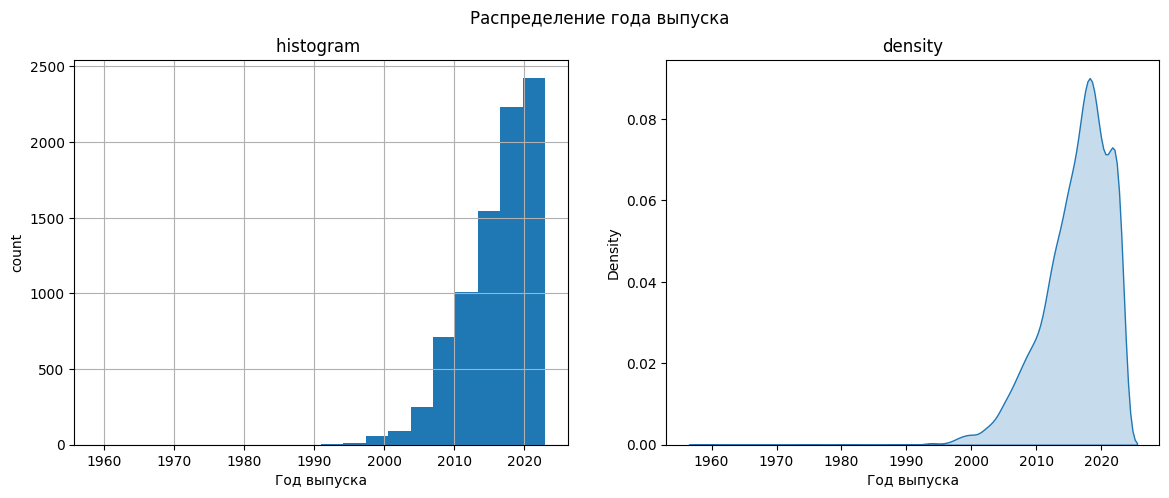

In [8]:
#Распределение признаков
#Создает новый график с заданным размером 14 на 5
plt.figure(figsize=(14, 5))
feature = 'Год выпуска'

#Сделай сетку 1x2 и переключись на левый график (позиция 1)
plt.subplot(121)
#df[feature] — берет столбец "Год выпуска"
#.hist() — строит гистограмму
#density=False — показывать абсолютные значения (количество), а не плотность вероятности
#bins=20 — разбить данные на 20 столбцов (интервалов)
df[feature].hist(density=False, bins=20)
#Подпиши вертикальную ось как 'Количество' а горизонтальную как "Год выпуска", и называние графика сверху
plt.ylabel('count')
plt.xlabel(feature)
plt.title('histogram ')

#Сделай сетку 1x2 и переключись на правый график (позиция 2)
plt.subplot(122)
#sns.kdeplot() — строит график плотности распределения (Kernel Density Estimation)
#df[feature] — берет столбец "Год выпуска" из DataFrame
#fill=True — закрашивает область под кривой цветом
#legend=False — не показывает легенду (чтобы не загромождать график)
sns.kdeplot(df[feature], fill=True, legend=False)
plt.xlabel(feature)
plt.title('density')
#Добавляет общий заголовок над всеми графиками
plt.suptitle('Распределение года выпуска')
plt.show()

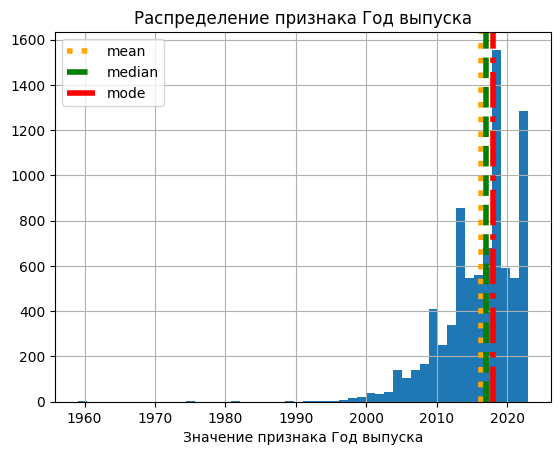

In [9]:
#Нарисуем среднее арифметическое медиану и моду
#Считает среднее арифметическое, округляет до 2 знаков после запятой
target_mean = round(df[feature].mean(), 2)
target_median = df[feature].median()
#Возвращает все моды, берет первую моду(самое часто встречающееся значение)
target_mode = df[feature].mode()[0]
#Строит гистограмму с 50 интервалами
graph = df[feature].hist(bins=50)
#Рисует вертикальну. линию(положение на оси x, подпись, стиль линии - пунктирная, толщина линии 4, цвет линии орандж
plt.axvline(x=target_mean, label='mean', linestyle=':', linewidth=4, color='orange')
plt.axvline(x=target_median, label='median', linestyle='--', linewidth=4, color='g')
plt.axvline(x=target_mode, label='mode', linestyle='-.', linewidth=4, color='r')

plt.title(f'Распределение признака {feature}')
plt.xlabel(f'Значение признака {feature}')
plt.legend()
plt.show()

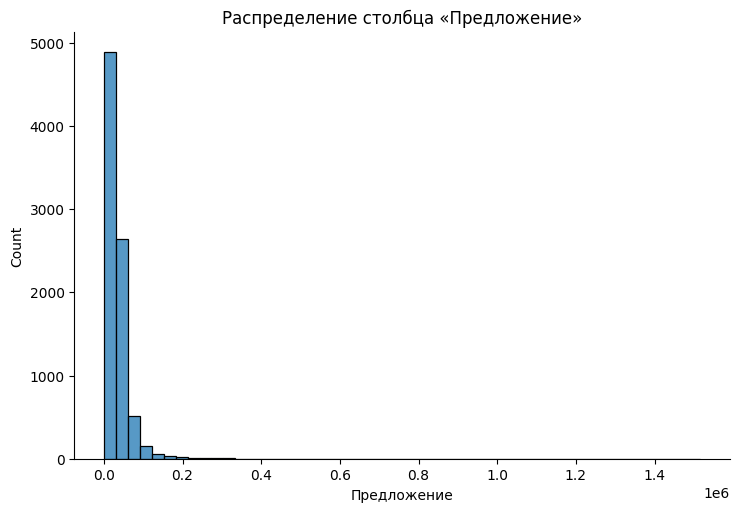

In [10]:
# Распределение вспомогательного столбца «Предложение» (целевая переменная модели — «Цена»), 50 интервалов, высота графика 5, aspect = ширина / высота, соотношение сторон
graph = sns.displot(df['Предложение'], bins=50, height=5, aspect=1.5)

plt.title("Распределение столбца «Предложение»")
plt.show()

In [11]:
#Смотрим типы признаков
df.dtypes

car_id                       str
Бренд                        str
Год выпуска              float64
Модель                       str
Тип машины                   str
Полное название              str
Исползование                 str
КПП                          str
Двигатель                    str
Привод                       str
Топливо                      str
Расход                       str
Пробег                       str
Цвет                         str
Локация                      str
Количество цилиндров         str
Тип кузова                   str
Двери                        str
Количество кресел            str
Оценка эксперта          float64
Количество владельцев    float64
Предложение              float64
dtype: object

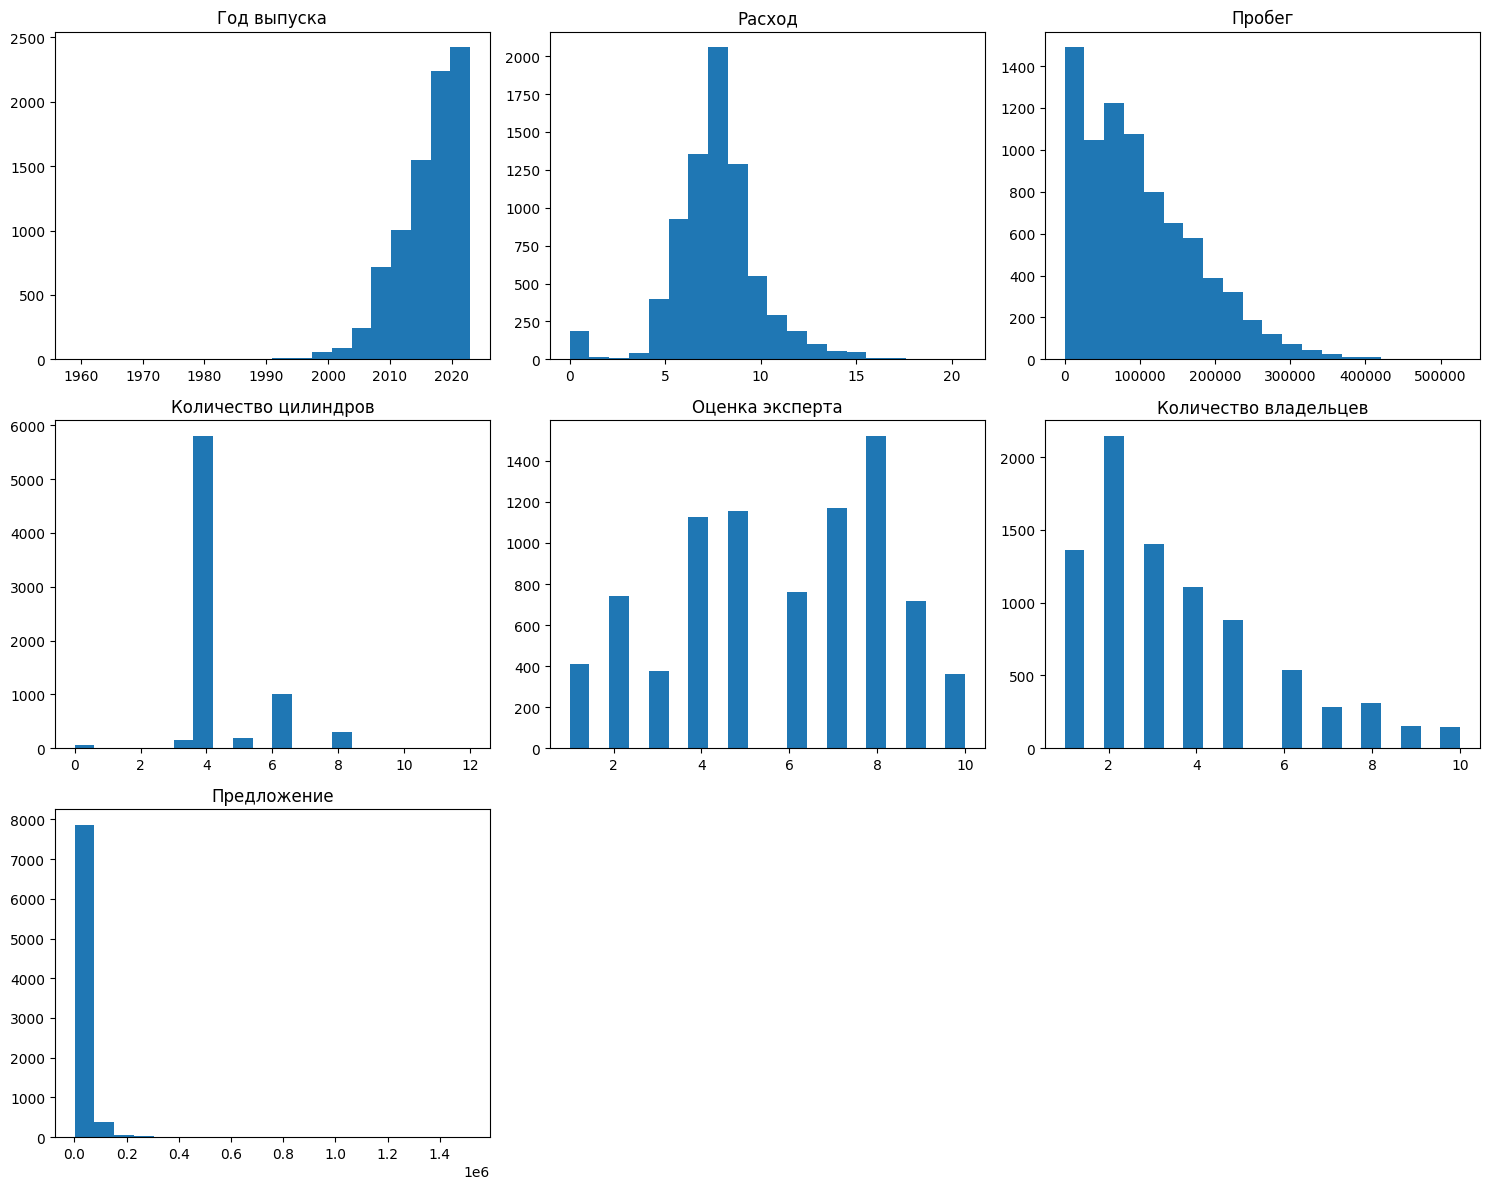

In [12]:
#Количественные признаки
df_num_features = df.copy() #Сделаем копию чтобы не влиять на исходные данные

#Преобразуем признаки, которые должны быть числовыми
#Пробуем преобразовать столбец в число pd.to_numeric()
#Если не получается ставим NaN (errors="coerce")
df_num_features["Пробег"] = pd.to_numeric(df_num_features["Пробег"], errors="coerce")
#.extract() извелекает подстроку по регулярному выражению
df_num_features["Расход"] = (df_num_features["Расход"].str.extract(r"(\d+\.?\d*)")[0])
df_num_features["Расход"] = pd.to_numeric(df_num_features["Расход"], errors="coerce")

df_num_features["Количество цилиндров"] = (df_num_features["Количество цилиндров"].str.extract(r"(\d+)")[0])
df_num_features["Количество цилиндров"] = pd.to_numeric(df_num_features["Количество цилиндров"], errors="coerce")

#Оставляем только числовые признаки
#select_dtypes() - выбирает столбцы по типу данных
#include="number" - оставляет только числовые типы (int, float)
df_num_features = df_num_features.select_dtypes(include="number")

#Строим гистограммы
df_num_features.hist(figsize=(15, 12), bins=20, grid=False)

plt.tight_layout()
plt.show()

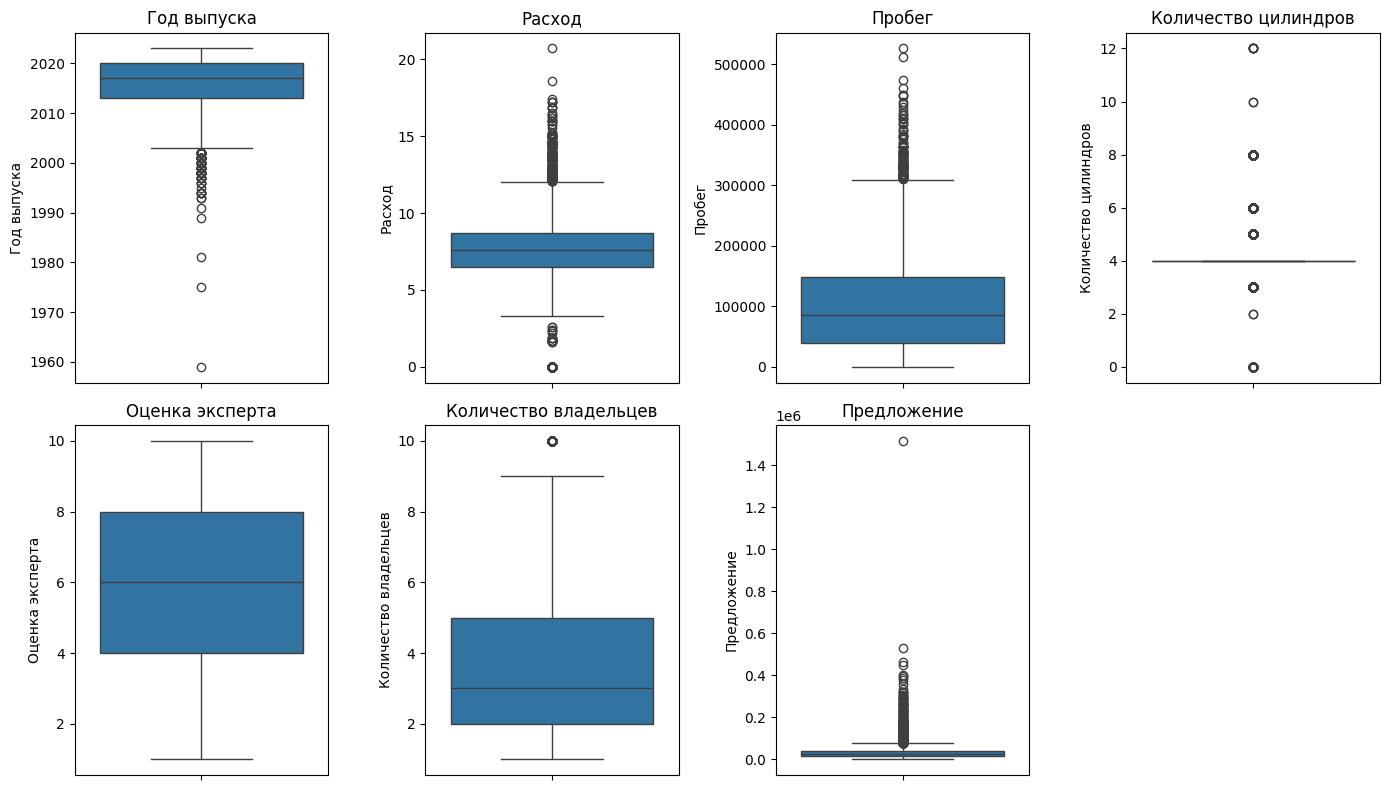

In [13]:
#Строим бокплоты
#Боксплоты для всех количественных признаков

numeric_cols = df_num_features.columns

#Создает график ширина 14 высота 8
plt.figure(figsize=(14, 8))

#Количество графиков, считает сколько числовых признаков
num_plots = len(numeric_cols)

#Размер сетки
#Рисуем боксплоты в 2 строки
nrows = 2
#Считаем сколько надо столбцов чтобы нарисовать в 2 строки с округлением вверх
ncols = (num_plots + nrows - 1) // nrows

#Строим боксплоты
#Пробегаемся по списку признаков
for i, feature in enumerate(numeric_cols):
    plt.subplot(nrows, ncols, i + 1)
    sns.boxplot(y=df_num_features[feature])
    plt.title(feature)

plt.tight_layout()
plt.show()

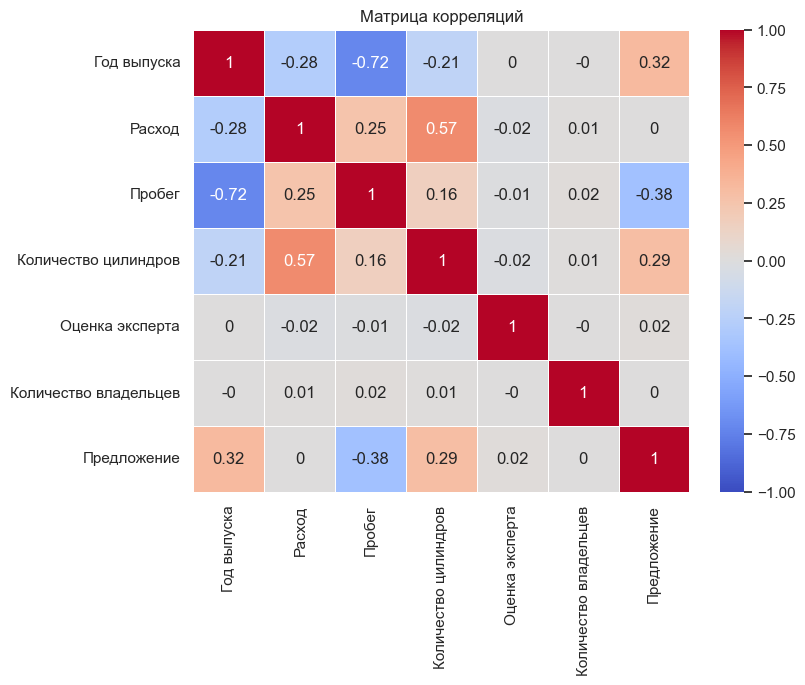

In [14]:
#Матрица корреляций
#Создает пустой график ширина 8 высота 6
plt.figure(figsize=(8, 6))
#устанавливает базовый масштаб шрифта 1 стандартный размер
sns.set(font_scale=1)
#.corr() — вычисляет парную корреляцию Пирсона между всеми числовыми столбцами
corr_matrix = df_num_features.corr()
#np.round() - округляет все значения в матрице до 2х знаков после запятой
corr_matrix = np.round(corr_matrix, 2)

sns.heatmap(
    corr_matrix,
    #Показывает числовые значения в каждой ячейке
    annot=True,
    #толщина линий между ячейками
    linewidths=0.5,
    cmap="coolwarm",
    #Устанавливаем от -1 до 1 то есть полный диапазон корреляции
    vmin=-1,
    vmax=1
)

plt.title("Матрица корреляций")
plt.show()

In [15]:
# Корреляция числовых признаков со столбцом «Предложение» (не с целевой «Цена»)
#.sort_values(ascending=False) - сортирует значения в столбце по убыванию
corr_target = (corr_matrix["Предложение"].sort_values(ascending=False))
#ascending=False — убывающий порядок
print(corr_target)

Предложение              1.00
Год выпуска              0.32
Количество цилиндров     0.29
Оценка эксперта          0.02
Расход                   0.00
Количество владельцев    0.00
Пробег                  -0.38
Name: Предложение, dtype: float64


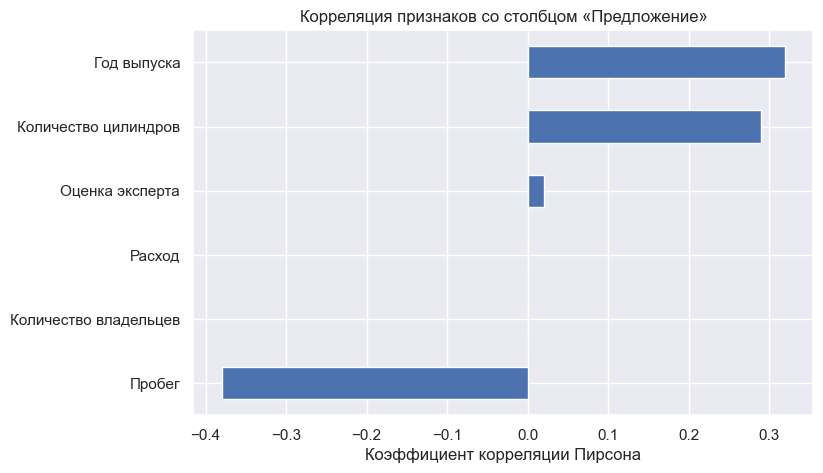

In [16]:
# Корреляция числовых признаков со столбцом «Предложение», а не с целевой «Цена»
#.drop() - удаляет указанный элемент из Series
target_corr = (corr_matrix["Предложение"].drop("Предложение").sort_values(ascending=False))
#Создает пустой график ширина 8 высота 5
plt.figure(figsize=(8, 5))
#kind="barh" - тип графика это горизонтальные столбцы
target_corr.plot(kind="barh")

plt.title("Корреляция признаков со столбцом «Предложение»")
plt.xlabel("Коэффициент корреляции Пирсона")

plt.gca().invert_yaxis()

plt.show()

# 3. Обучение Random Forest и оценка качества

Целевая переменная — `Цена` из таблицы `y_train_base.csv`. Случайное разделение 80/20; значения для заполнения пропусков и категории One-Hot Encoder вычисляются **только по обучающей выборке**.

Ниже сохранены результаты исходного локального эксперимента: лучшая из шести конфигураций Random Forest дала **MAPE 20,37%** и **MAE 6 593,63** на валидационной выборке. Валидация также использовалась для выбора параметров, поэтому эту оценку нельзя считать результатом независимого финального тестирования.

In [17]:
#Добавим RandomForest
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.preprocessing import OneHotEncoder

#Папка куда буду сохранять результаты
output_root = Path("outputs")
output_root.mkdir(parents=True, exist_ok=True)

#Выводим максимум 300 строк и столбцов
pd.options.display.max_columns = 300
pd.options.display.max_rows = 300
pd.options.display.max_colwidth = 300

#Загружаем данные
X_train = pd.read_csv(root / "full_dataset.csv")
y_train = pd.read_csv(root / "y_train_base.csv")
X_test = pd.read_csv(root / "X_test_base.csv")

#Метод shape возвращается размерность data_frame в виде кортежа 
print("Размер full_dataset:", X_train.shape)
print("Размер y_train:", y_train.shape)
print("Размер X_test:", X_test.shape)

#Объединяем признаки с целевой переменной в одну таблицу
train = X_train.merge(
    #merge это метод Pandas который объединяет два data_frame по общему столбцу
    y_train,
    #Объединяем строки у которых совпадает car_id
    on="car_id",
    #Оставляем только те автомобили которые есть в обоих таблицах
    how="inner"
)

print("\nРазмер после объединения:")
print(train.shape)

#Подготавливаем числовые признаки
#Пробег
#pd.to_numeric() преобразует в числовой тип, errors="coerce" ставим NaN если не получилось
train["Пробег"] = pd.to_numeric(train["Пробег"], errors="coerce")
X_test["Пробег"] = pd.to_numeric(X_test["Пробег"], errors="coerce")

#Расход
#.extract() извлекает подстроку по регулярному выражению, [0] - берем первую колонку из результата extract
train["Расход"] = train["Расход"].str.extract(r"(\d+\.?\d*)")[0]
train["Расход"] = pd.to_numeric(train["Расход"], errors="coerce")

X_test["Расход"] = X_test["Расход"].str.extract(r"(\d+\.?\d*)")[0]
X_test["Расход"] = pd.to_numeric(X_test["Расход"], errors="coerce")

#Количество цилиндров
train["Количество цилиндров"] = train["Количество цилиндров"].str.extract(r"(\d+)")[0]
train["Количество цилиндров"] = pd.to_numeric(train["Количество цилиндров"], errors="coerce")

X_test["Количество цилиндров"] = X_test["Количество цилиндров"].str.extract(r"(\d+)")[0]
X_test["Количество цилиндров"] = pd.to_numeric(X_test["Количество цилиндров"], errors="coerce")

#Год выпуска
train["Год выпуска"] = pd.to_numeric(train["Год выпуска"], errors="coerce")
X_test["Год выпуска"] = pd.to_numeric(X_test["Год выпуска"], errors="coerce")

#Признаки
#Создаем числовые признаки
numeric_features = [
    "Год выпуска",
    "Пробег",
    "Расход",
    "Количество цилиндров",
    "Оценка эксперта",
    "Количество владельцев"
]
#Создаем категориальные признаки
categorical_features = [
    "Бренд",
    "Топливо",
    "КПП",
    "Привод",
    "Тип кузова"
]
#Объединяем 2 списка в один
features = numeric_features + categorical_features
#Создаем матрицу признаков, .copy() создает копию данных, чтобы не изменить оригинал
X = train[features].copy()
#Создаем целевую переменную
y = train["Цена"]
#В тестовых данных такие же признаки что и в X 
X_test_model = X_test[features].copy()

#Делим выборку на обучающую и валидационную
#Размер тестовой выборки 20%, 
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=52)

#Получаем уникальные значения для брендов и типов кузова
unique_brands = sorted(X_train["Бренд"].dropna().unique())
unique_body_types = sorted(X_train["Тип кузова"].dropna().unique())

print("Доступные бренды:", unique_brands[:10])  # выведем первые 10 для проверки
print("Доступные типы кузова:", unique_body_types[:10])

#Заполняем пропуски(NaN) медианой в числовых признаках
#используем медиану из обучающих данных для всех трёх наборов
median_values = X_train[numeric_features].median()
X_train[numeric_features] = X_train[numeric_features].fillna(median_values)
X_valid[numeric_features] = X_valid[numeric_features].fillna(median_values)
X_test_model[numeric_features] = X_test_model[numeric_features].fillna(median_values)

#Заполняем пропуски(NaN) модой в категориальных признаках
#используем моду из обучающих данных для всех трёх наборов
#.iloc[0] — берёт первую моду если их несколько
mode_values = X_train[categorical_features].mode().iloc[0]
X_train[categorical_features] = X_train[categorical_features].fillna(mode_values)
X_valid[categorical_features] = X_valid[categorical_features].fillna(mode_values)
X_test_model[categorical_features] = X_test_model[categorical_features].fillna(mode_values)

#One-Hot Encoding
#Преобразуем категориальные признаки в числовой формат с помощью OneHotEncoder
encoder = OneHotEncoder(
    #Если встретиться неизвестная категория которой не было в обучении то игнорирует
    handle_unknown="ignore",
    sparse_output=False
)
#fit_transform - запоминает все уникальные категории из обучающих данных и преобразует категории в бинарные столбцы
#Создаем переменные для закодированных категорий
X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_valid_cat = encoder.transform(X_valid[categorical_features])
X_test_cat = encoder.transform(X_test_model[categorical_features])

#Объединяем закодированные признаки с числовыми
#hstack = horizontal stack (горизонтальное объединение) склеивает два массива по горизонтали (добавляет новые столбцы справа).
X_train = np.hstack([X_train[numeric_features].values, X_train_cat])
X_valid = np.hstack([X_valid[numeric_features].values, X_valid_cat])
X_test_model = np.hstack([X_test_model[numeric_features].values, X_test_cat])
#Хочу посмотреть новый размер
print("\nРазмер после One-Hot Encoding:")
print(X_test_model.shape)

#Подбор параметров Random Forest
#max_depth — максимальная глубина дерева (None = без ограничений)
#min_samples_leaf — минимальное количество объектов в листе
#min_samples_split — минимальное количество объектов для разбиения
params = [
    (None, 1, 2), # (max_depth, min_samples_leaf, min_samples_split)
    (None, 2, 5),
    (20, 2, 5),
    (15, 2, 5),
    (12, 2, 5),
    (10, 2, 5),
]

#Здесь будет храниться лучшая модель
best_model = None
#Начнем с бесконечности
best_mape = float("inf")

print("\nПодбор параметров Random Forest:\n")
#Цикл перебирает 6 комбинаций параметров
for max_depth, min_leaf, min_split in params:

    model = RandomForestRegressor(
        random_state=52,
        #1000 деревьев в лесу
        n_estimators = 1000,
        #Максимальная грубина каждого дерева
        max_depth = max_depth,
        #Минимальное количество объектов в листовом узле
        min_samples_leaf = min_leaf,
        #Минимальное количество объектов для разбиения узла
        min_samples_split = min_split,
        #Количество признаков для каждого дерева это корень
        max_features = "sqrt",
        #Использует все ядра процессора, учиться быстрее всего
        n_jobs=-1
    )
    
    #Обучаем модель
    model.fit(X_train, y_train)
    #Предсказываем цены на валидационной выборке
    pred = model.predict(X_valid)
    
    #Создаем метрики для сравнения
    #Mean Absolute Error
    mae = mean_absolute_error(y_valid, pred)
    #Mean Absolute Percentage Error
    mape = mean_absolute_percentage_error(y_valid, pred)
    #Выводим параметры модели и метрики
    print(
        f"depth={max_depth}, "
        f"leaf={min_leaf}, "
        f"split={min_split} "
        f"-> MAE={mae:.2f}, "
        f"MAPE={mape:.4f}"
    )
    #Если текущая MAPE меньше, чем лучшая найденная то сохраняем значения
    if mape < best_mape:
        best_mape = mape
        best_model = model
        best_params = (max_depth, min_leaf, min_split)

#Берем лучшую модель которая у нас получилась
model = best_model
#Выводим ее параметры
print("\nЛучшая модель:")
print(f"max_depth = {best_params[0]}")
print(f"min_samples_leaf = {best_params[1]}")
print(f"min_samples_split = {best_params[2]}")
#Предсказываем цены на валидационной выборке
prediction_valid = model.predict(X_valid)

#Добавляем метрики
mae = mean_absolute_error(y_valid, prediction_valid)
mape = mean_absolute_percentage_error(y_valid, prediction_valid)

print(f"MAE  = {mae:.2f}")
print(f"MAPE = {mape:.4f}")
print(f"MAPE = {mape * 100:.2f}%")

#Предсказание тестовой выборки
y_test = model.predict(X_test_model)
submission = pd.DataFrame({"Цена": y_test})
submission.to_csv(output_root / "submission_random_forest.csv", index=False)

#Архивируем
with zipfile.ZipFile(output_root / "submission_random_forest.zip", "w", zipfile.ZIP_DEFLATED
) as zipf:
    zipf.write(output_root / "submission_random_forest.csv", arcname="submission.csv")

Размер full_dataset: (8340, 22)
Размер y_train: (8340, 2)
Размер X_test: (8341, 22)

Размер после объединения:
(8340, 23)
Доступные бренды: ['ABARTH', 'ALFA', 'ASTON', 'AUDI', 'BENTLEY', 'BMW', 'BYD', 'CATERHAM', 'CHERY', 'CHEVROLET']
Доступные типы кузова: ['COMMERCIAL', 'CONVERTIBLE', 'COUPE', 'HATCHBACK', 'OTHER', 'PEOPLE MOVER', 'SEDAN', 'SUV', 'UTE / TRAY', 'WAGON']

Размер после One-Hot Encoding:
(8341, 98)

Подбор параметров Random Forest:

depth=None, leaf=1, split=2 -> MAE=6593.63, MAPE=0.2037
depth=None, leaf=2, split=5 -> MAE=7771.98, MAPE=0.2537
depth=20, leaf=2, split=5 -> MAE=7907.86, MAPE=0.2592
depth=15, leaf=2, split=5 -> MAE=8412.27, MAPE=0.2856
depth=12, leaf=2, split=5 -> MAE=9103.74, MAPE=0.3196
depth=10, leaf=2, split=5 -> MAE=9798.50, MAPE=0.3560

Лучшая модель:
max_depth = None
min_samples_leaf = 1
min_samples_split = 2
MAE  = 6593.63
MAPE = 0.2037
MAPE = 20.37%


# 4. Функция предсказания

На вход подаются основные характеристики автомобиля. Другие используемые моделью признаки заполняются значениями, вычисленными по обучающей выборке. Это упрощённая демонстрация: точность при неполных входных данных отдельно не оценивалась.

In [18]:
#Функция принимает параметры: Год выпуска, Пробег, Количество владельцев, Бренд, Тип кузова, Привод
def predict_price(year_of_release, mileage, number_of_owners, brand, body_type, drive):
    #Создаем словарь для данных
    input_dictionary = {}
    
    #Числовые признаки
    #Пробегаем по всем числовым признакам
    for feature in numeric_features:
        if feature == "Год выпуска":
            input_dictionary[feature] = year_of_release
        elif feature == "Пробег":
            input_dictionary[feature] = mileage
        elif feature == "Количество владельцев":      
            input_dictionary[feature] = number_of_owners
        else:
            #Для всех остальных числовых признаков заполняем медианой
            input_dictionary[feature] = median_values[feature]
    
    #Категориальные признаки
    #Пробегаем по всем категориальным признакам
    for feature in categorical_features:
        if feature == "Бренд":
            input_dictionary[feature] = brand
        elif feature == "Тип кузова":
            input_dictionary[feature] = body_type
        elif feature == "Привод":                     
            input_dictionary[feature] = drive
        else:
            #Для всех остальных категориальных признаков заполняем модой
            input_dictionary[feature] = mode_values[feature]
    
    #Создаём data_frame с правильным порядком колонок c помощью [features]
    input_data_frame = pd.DataFrame([input_dictionary])[features]
    
    #Извлекаем числовые признаки
    X_num = input_data_frame[numeric_features].values
    #Кодируем категориальные признаки(One_hot_encoding) превращаем текст в числа
    X_cat = encoder.transform(input_data_frame[categorical_features])
    #Склеиваем числовую и категориальную части
    X_input = np.hstack([X_num, X_cat])
    #Делаем предсказание
    pred = model.predict(X_input)
    
    return f"Предсказанная цена: {pred[0]:,.2f} (единицы исходных данных)"

# 5. Демонстрационный интерфейс на Gradio

Интерфейс запускается **локально**. GitHub показывает код, но не поддерживает работу Gradio прямо внутри просмотрщика `.ipynb`. Для использования интерфейса нужно запустить ноутбук на своём компьютере.

In [19]:
import gradio as gr

#Загружаем исходный датасет
full_df = pd.read_csv(root / "full_dataset.csv")
#full_df = pd.read_csv(root / "X_test_base.csv")
#Извлекаем все уникальные значения из колонок
#.dropna() удаляет пустые значения (NaN)
#.unique() получает все уникальные значения
#sorted() — сортирует по алфавиту
unique_brands = sorted(full_df["Бренд"].dropna().unique())
unique_body_types = sorted(full_df["Тип кузова"].dropna().unique())
unique_drives = sorted(full_df["Привод"].dropna().unique())

#Интерфейс
#минимальное и максимальное значение, шаг изменения, значение по умолчанию, подпись над ползунком
year_input = gr.Slider(1990, 2025, step=1, value=2025, label="Год выпуска")
mileage_input = gr.Slider(0, 300000, step=1000, value=50000, label="Пробег (км)")
number_of_owners_input = gr.Slider(0, 10, step=1, value=1, label="Количество владельцев")
#варианты для выбора, значение по умолчанию, подпись над списком
brand_input = gr.Dropdown(choices=unique_brands, value=unique_brands[0], label="Бренд")
body_type_input = gr.Dropdown(choices=unique_body_types, value=unique_body_types[0], label="Тип кузова")
drive_input = gr.Dropdown(choices=unique_drives, value=unique_drives[0], label="Привод")  

#Примеры машин
examples = [
    [2018, 29030, 2, "SUBARU", "SEDAN", "AWD"],
    [2023, 7, 2, "SSANGYONG", "SUV", "AWD"],
    [2008, 282382, 3, "MAZDA", "SEDAN", "Front"]
]

demo = gr.Interface(
    fn=predict_price,
    inputs=[year_input, mileage_input, number_of_owners_input, brand_input, body_type_input, drive_input],
    outputs="text",
    title="Оценка стоимости автомобиля",
    description="Введите характеристики автомобиля для предсказания цены.",
    examples=examples
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


# 6. Ограничения и дальнейшие улучшения

- Провести независимое тестирование после подбора гиперпараметров или использовать кросс-валидацию.
- Проверить корректность объединения нескольких записей одного `car_id` через `groupby(...).first()`.
- Исследовать зависимость именно целевой переменной `Цена` от признаков; текущий корреляционный анализ касается столбца `Предложение`.
- Уточнить исходную валюту цены и не подписывать прогноз как сумму в рублях без подтверждения.
- Вынести предобработку и модель в единый `Pipeline`, добавить тесты и воспроизводимые версии зависимостей.

**Важно:** выводы ноутбука получены в исходном локальном запуске. В этой версии исправлены пути и подписи, но повторно обучить модель без исходных данных невозможно.